# Business Services and Microsoft Peer Analysis

**BAIT 508 · Group 26 · UBC Sauder Master of Business Analytics**

This notebook combines public-firm financial records with Form 10-K Item 1 business descriptions. It profiles Business Services (SIC major group 73), compares filing language in 2020 and 2025, and selects a text-based peer group for Microsoft before benchmarking its financials.

Open the notebook to see saved tables and figures. To rerun it, follow the repository README, place the four original course CSVs in `data/`, and start JupyterLab from the repository root. The two Word2Vec training runs can take longer than the other steps.


In [ ]:
from pathlib import Path

data_dir = Path("data")
required_files = (
    "major_groups.csv",
    "public_firms.csv",
    "2020_10K_item1_full.csv",
    "2025_10K_item1_full.csv",
)
missing_files = [name for name in required_files if not (data_dir / name).is_file()]

if missing_files:
    raise FileNotFoundError(
        "Start JupyterLab from the repository root and place these course CSVs "
        "in data/: " + ", ".join(missing_files)
    )


## 1. Profile Business Services firms

Filter public-firm observations to SIC major group 73. Count distinct firms and firm-years, inspect the distribution of prices, sales and locations, and calculate annual mean return on assets for U.S. firms.


In [1]:
import pandas as pd

groups = pd.read_csv(data_dir / "major_groups.csv")
firms = pd.read_csv(data_dir / "public_firms.csv")

# Select Business Services.
industry_code = int(
    groups.loc[
        groups["description"].str.strip().str.casefold()
        == "business services",
        "major_group",
    ].iloc[0]
)

# The first two digits of a four-digit SIC code identify its major group.
sic = pd.to_numeric(firms["sic"], errors="coerce")
filtered = firms.loc[(sic // 100) == industry_code].copy()

# Identify unique firm-year observations using gvkey and fyear.
firm_years = filtered[["gvkey", "fyear"]].drop_duplicates()

# a. Number of unique firm-year observations.
a = len(firm_years)

# b. Number of unique firms.
b = firm_years["gvkey"].nunique()

# c. Firms observed in every required year.
required_years = set(range(1994, 2026))
complete_firms = firm_years.groupby("gvkey")["fyear"].agg(
    lambda years: required_years.issubset(set(years))
)
c = int(complete_firms.sum())

print(f"Industry: Business Services (code {industry_code})")
print(f"a. Unique firm-year observations: {a:,}")
print(f"b. Unique firms: {b:,}")
print(f"c. Firms with all 32 years (1994–2025): {c:,}")

Industry: Business Services (code 73)
a. Unique firm-year observations: 30,610
b. Unique firms: 3,273
c. Firms with all 32 years (1994–2025): 64


In [2]:
for year in [2020, 2025]:
    top_10 = (
        filtered.loc[filtered["fyear"] == year]
        .dropna(subset=["prcc_c"])
        .nlargest(10, "prcc_c")
        [["conm", "prcc_c"]]
        .reset_index(drop=True)
    )

    top_10.index += 1
    print(f"\nTop 10 firms by stock price in {year}")
    display(top_10)


Top 10 firms by stock price in 2020


,conm,prcc_c
1,ALPHABET INC,1752.64
2,CONSTELLATION SOFTWARE INC,1303.04
3,SHOPIFY INC,1131.95
4,COSTAR GROUP INC,924.28
5,TRADE DESK INC,801.00
6,SERVICENOW INC,550.43
7,FAIR ISAAC CORP,511.04
8,ADOBE INC,500.12
9,PAYCOM SOFTWARE INC,452.25
10,TYLER TECHNOLOGIES INC,436.52



Top 10 firms by stock price in 2025


,conm,prcc_c
1,CONSTELLATION SOFTWARE INC,2399.743
2,FAIR ISAAC CORP,1690.620
3,UNITED RENTALS INC,809.320
4,APPLOVIN CORP,673.820
5,INTUIT INC,662.420
6,META PLATFORMS INC,660.090
7,SPOTIFY TECHNOLOGY SA,580.710
8,MASTERCARD INC,570.880
9,CACI INTL INC -CL A,532.810
10,S&P GLOBAL INC,522.590


In [3]:
top_sales = (
    filtered.dropna(subset=["sale"])
    .sort_values(["sale", "fyear"], ascending=[False, True])
    .drop_duplicates(subset="gvkey")
    .head(10)
    [["conm", "fyear", "sale"]]
    .reset_index(drop=True)
)

top_sales.index += 1
display(top_sales)

,conm,fyear,sale
1,ALPHABET INC,2025,402836.000
2,MICROSOFT CORP,2025,281724.000
3,META PLATFORMS INC,2025,200966.000
4,INTL BUSINESS MACHINES CORP,2011,106916.000
5,ORACLE CORP,2025,67357.000
6,FUJITSU LTD,2010,54717.315
7,NEC CORP,1999,48460.650
8,SAP SE,2025,43207.817
9,SALESFORCE INC,2025,41525.000
10,LUCENT TECHNOLOGIES INC,1999,38303.000


In [4]:
top_locations = (
    filtered.groupby("location")["gvkey"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="number_of_firms")
)

display(top_locations)

,location,number_of_firms
0,USA,2684
1,CHN,152
2,CAN,80
3,ISR,76
4,GBR,56
5,HKG,39
6,SGP,33
7,JPN,22
8,IRL,15
9,NLD,11


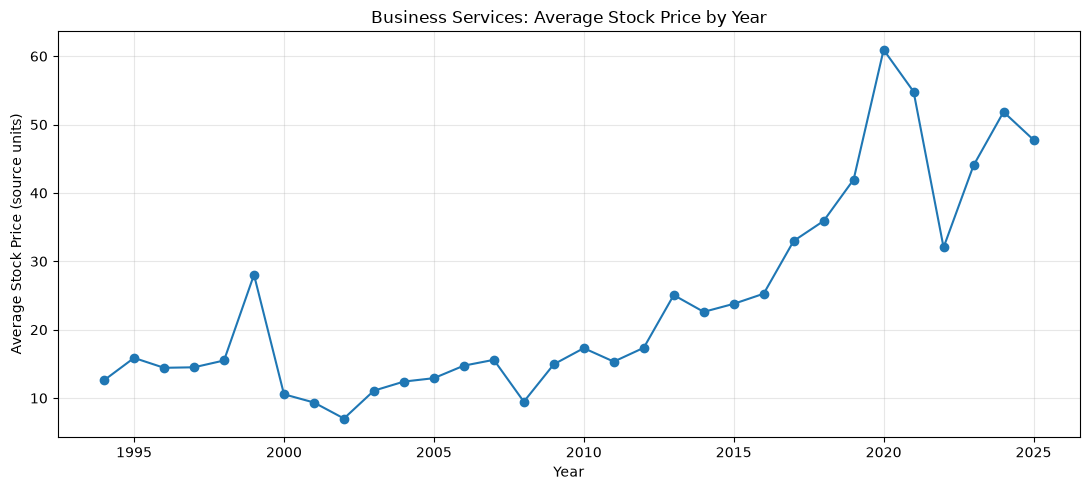

In [5]:
import matplotlib.pyplot as plt
average_price = (
    filtered.groupby("fyear")["prcc_c"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(11, 5))
plt.plot(average_price.index, average_price.values, marker="o")
plt.title("Business Services: Average Stock Price by Year")
plt.xlabel("Year")
plt.ylabel("Average Stock Price (source units)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
crisis_prices = (
    filtered.loc[filtered["fyear"].isin([2007, 2008])]
    .pivot(index="gvkey", columns="fyear", values="prcc_c")
    .dropna(subset=[2007, 2008])
)

# A positive starting price is required for this calculation.
crisis_prices = crisis_prices.loc[crisis_prices[2007] > 0].copy()

crisis_prices["percentage_drop"] = (
    (crisis_prices[2007] - crisis_prices[2008])
    / crisis_prices[2007]
    * 100
)

# Include all firms tied for the largest drop.
worst_affected = crisis_prices.loc[
    crisis_prices["percentage_drop"]
    == crisis_prices["percentage_drop"].max()
].reset_index()

firm_names = filtered[["gvkey", "conm"]].drop_duplicates("gvkey")

worst_affected = worst_affected.merge(firm_names, on="gvkey")

display(
    worst_affected[
        ["gvkey", "conm", 2007, 2008, "percentage_drop"]
    ].rename(columns={2007: "price_2007", 2008: "price_2008"})
)

,gvkey,conm,price_2007,price_2008,percentage_drop
0,183139,ACCESS NEWSWIRE INC,1.25,0.0071,99.432


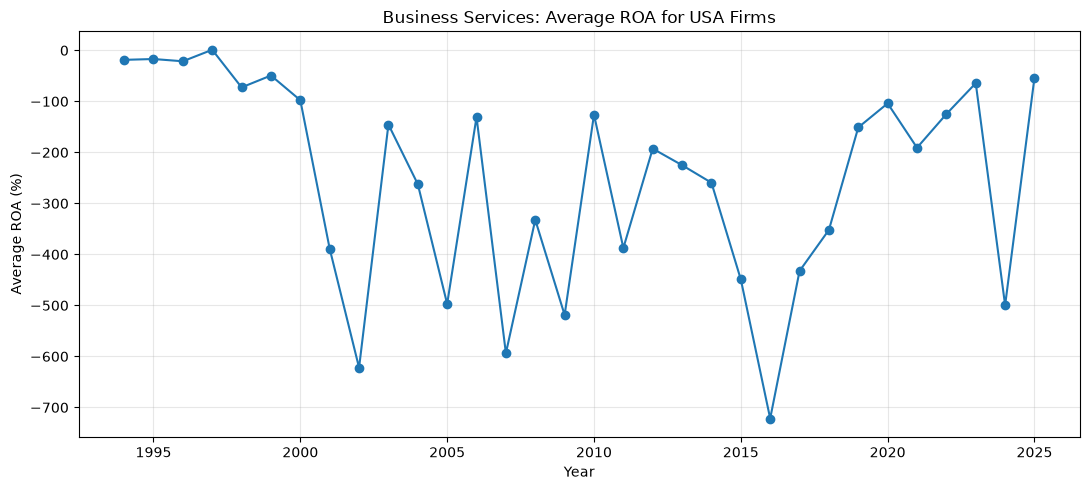

In [7]:
import matplotlib.pyplot as plt
usa_firms = filtered.loc[filtered["location"] == "USA"].copy()

usa_firms["ROA"] = (
    usa_firms["net_income"]
    / usa_firms["asset"].replace(0, float("nan"))
)

average_roa = (
    usa_firms.groupby("fyear")["ROA"]
    .mean()
    .sort_index()
    * 100
)

plt.figure(figsize=(11, 5))
plt.plot(average_roa.index, average_roa.values, marker="o")
plt.title("Business Services: Average ROA for USA Firms")
plt.xlabel("Year")
plt.ylabel("Average ROA (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Extract keywords from 2020 filings

Join Item 1 descriptions to firms using `gvkey`. Clean and deduplicate the text, then compare raw term counts with TF-IDF. The full firm representations are reused in the Microsoft peer analysis.


In [8]:
import pandas as pd
from IPython.display import display

groups = pd.read_csv(data_dir / "major_groups.csv")
firms = pd.read_csv(data_dir / "public_firms.csv")
reports = pd.read_csv(data_dir / "2020_10K_item1_full.csv")

# Standardize the merge key in both datasets.
for df in [firms, reports]:
    df["gvkey"] = pd.to_numeric(
        df["gvkey"], errors="coerce"
    ).astype("Int64")

firms["fyear"] = pd.to_numeric(firms["fyear"], errors="coerce")
firms["sic"] = pd.to_numeric(firms["sic"], errors="coerce")
reports["year"] = pd.to_numeric(reports["year"], errors="coerce")

industry_code = int(
    groups.loc[
        groups["description"].str.strip().str.casefold()
        == "business services",
        "major_group"
    ].iloc[0]
)

# Use each firm's 2020 industry classification.
sector_firms = firms.loc[
    (firms["fyear"] == 2020)
    & ((firms["sic"] // 100) == industry_code),
    ["gvkey", "conm", "sic", "location"]
].dropna(subset=["gvkey"]).copy()

assert sector_firms["gvkey"].is_unique

# Combine distinct filing texts for each firm.
# Exact duplicate texts are included only once.
reports_2020 = reports.loc[
    reports["year"] == 2020, ["gvkey", "item_1"]
].dropna(subset=["gvkey"]).copy()

reports_2020["item_1"] = reports_2020["item_1"].fillna("").astype(str)

firm_reports = (
    reports_2020.groupby("gvkey", as_index=False)
    .agg(
        item_1=(
            "item_1",
            lambda texts: " ".join(
                dict.fromkeys(
                    text.strip() for text in texts if text.strip()
                )
            )
        )
    )
)

# Inner join: retain firms present in both datasets.
business_services = sector_firms.merge(
    firm_reports,
    on="gvkey",
    how="inner",
    validate="one_to_one"
)

assert business_services["gvkey"].is_unique

print(f"Business Services firms with matched reports: {len(business_services):,}")

Business Services firms with matched reports: 482


In [9]:
import re
import unicodedata
from nltk.corpus import stopwords

english_stopwords = set(stopwords.words("english"))

def clean_text(text):
    text = str(text).lower()

    # Replace punctuation with spaces.
    text = "".join(
        " " if unicodedata.category(char).startswith("P") else char
        for char in text
    )

    # Exclude numbers and single-character fragments.
    words = re.findall(r"\b[a-z]{2,}\b", text)

    return " ".join(
        word for word in words if word not in english_stopwords
    )

business_services["cleaned_text"] = (
    business_services["item_1"].apply(clean_text)
)

# Keep the merged DataFrame intact; analyze nonempty documents.
analysis_firms = business_services.loc[
    business_services["cleaned_text"].str.strip().ne("")
].reset_index(drop=True).copy()

print(f"Firms with usable text: {len(analysis_firms):,}")

Firms with usable text: 482


In [10]:
import numpy as np
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfTransformer
)

if analysis_firms.empty:
    raise ValueError("No usable text remains after cleaning.")

# Build a shared vocabulary for both methods.
count_vectorizer = CountVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b[a-z]{2,}\b"
)

count_matrix = count_vectorizer.fit_transform(
    analysis_firms["cleaned_text"]
)
terms = count_vectorizer.get_feature_names_out()

# Default TF-IDF uses smoothed IDF and L2 normalization.
tfidf_transformer = TfidfTransformer()
tfidf_matrix = tfidf_transformer.fit_transform(count_matrix)

def top_keywords_table(matrix, score_name):
    rows = []

    for i in range(matrix.shape[0]):
        document = matrix.getrow(i)

        # Sort by score descending, then alphabetically for ties.
        positions = sorted(
            range(len(document.data)),
            key=lambda j: (
                -document.data[j],
                terms[document.indices[j]]
            )
        )[:10]

        for rank, j in enumerate(positions, start=1):
            score = document.data[j]

            rows.append({
                "gvkey": analysis_firms.loc[i, "gvkey"],
                "firm": analysis_firms.loc[i, "conm"],
                "rank": rank,
                "keyword": terms[document.indices[j]],
                score_name: (
                    int(score) if score_name == "word_count"
                    else float(score)
                )
            })

    return pd.DataFrame(rows)

top10_counts = top_keywords_table(count_matrix, "word_count")
top10_tfidf = top_keywords_table(tfidf_matrix, "tfidf_score")

# Each table contains up to 10 keywords per firm.
print("Word-count keywords — first three firms")
display(top10_counts.head(30))

print("TF-IDF keywords — first three firms")
display(top10_tfidf.head(30).round({"tfidf_score": 4}))

Word-count keywords — first three firms


,gvkey,firm,rank,keyword,word_count
0,1084,WORLDS INC,1,company,181
1,1084,WORLDS INC,2,cannabis,94
2,1084,WORLDS INC,3,inc,37
3,1084,WORLDS INC,4,worlds,37
4,1084,WORLDS INC,5,state,31
5,1084,WORLDS INC,6,hemp,29
6,1084,WORLDS INC,7,products,27
7,1084,WORLDS INC,8,gencanna,23
8,1084,WORLDS INC,9,management,21
9,1084,WORLDS INC,10,cbd,19


TF-IDF keywords — first three firms


,gvkey,firm,rank,keyword,tfidf_score
0,1084,WORLDS INC,1,cannabis,0.6603
1,1084,WORLDS INC,2,company,0.2742
2,1084,WORLDS INC,3,worlds,0.2552
3,1084,WORLDS INC,4,hemp,0.2373
4,1084,WORLDS INC,5,gencanna,0.2191
5,1084,WORLDS INC,6,cbd,0.1504
6,1084,WORLDS INC,7,marimed,0.1239
7,1084,WORLDS INC,8,worldsplayer,0.0953
8,1084,WORLDS INC,9,cultivation,0.0951
9,1084,WORLDS INC,10,seed,0.0871


In [11]:
# Replace with a firm name or part of its name.
firm_search = "Microsoft"

display(
    top10_counts.loc[
        top10_counts["firm"].str.contains(
            firm_search, case=False, na=False, regex=False
        )
    ]
)

display(
    top10_tfidf.loc[
        top10_tfidf["firm"].str.contains(
            firm_search, case=False, na=False, regex=False
        )
    ].round({"tfidf_score": 4})
)

,gvkey,firm,rank,keyword,word_count
390,12141,MICROSOFT CORP,1,services,106
391,12141,MICROSOFT CORP,2,microsoft,68
392,12141,MICROSOFT CORP,3,products,65
393,12141,MICROSOFT CORP,4,cloud,59
394,12141,MICROSOFT CORP,5,business,54
395,12141,MICROSOFT CORP,6,software,46
396,12141,MICROSOFT CORP,7,customers,45
397,12141,MICROSOFT CORP,8,devices,44
398,12141,MICROSOFT CORP,9,solutions,44
399,12141,MICROSOFT CORP,10,including,43


,gvkey,firm,rank,keyword,tfidf_score
390,12141,MICROSOFT CORP,1,microsoft,0.3069
391,12141,MICROSOFT CORP,2,windows,0.2524
392,12141,MICROSOFT CORP,3,services,0.2187
393,12141,MICROSOFT CORP,4,cloud,0.1740
394,12141,MICROSOFT CORP,5,xbox,0.1636
395,12141,MICROSOFT CORP,6,gaming,0.1634
396,12141,MICROSOFT CORP,7,server,0.1612
397,12141,MICROSOFT CORP,8,devices,0.1430
398,12141,MICROSOFT CORP,9,products,0.1430
399,12141,MICROSOFT CORP,10,president,0.1314


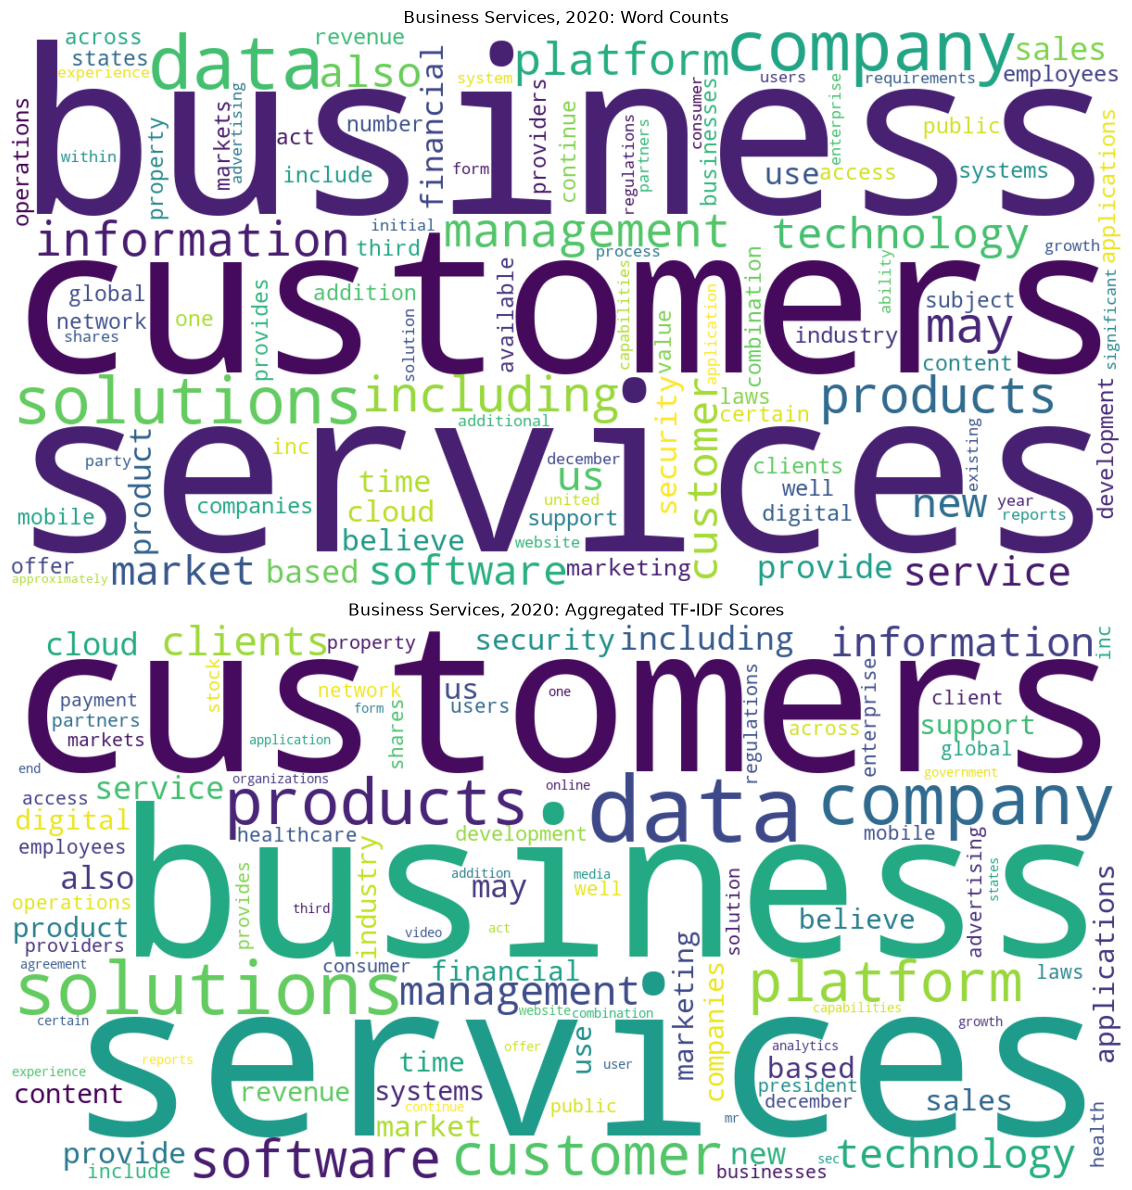

In [12]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

sector_counts = np.asarray(count_matrix.sum(axis=0)).ravel()
sector_tfidf = np.asarray(tfidf_matrix.sum(axis=0)).ravel()

count_frequencies = {
    term: float(score)
    for term, score in zip(terms, sector_counts)
    if score > 0
}

tfidf_frequencies = {
    term: float(score)
    for term, score in zip(terms, sector_tfidf)
    if score > 0
}

count_cloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100,
    collocations=False,
    random_state=42
).generate_from_frequencies(count_frequencies)

tfidf_cloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100,
    collocations=False,
    random_state=42
).generate_from_frequencies(tfidf_frequencies)

fig, axes = plt.subplots(2, 1, figsize=(14, 12))

axes[0].imshow(count_cloud, interpolation="bilinear")
axes[0].set_title("Business Services, 2020: Word Counts")
axes[0].axis("off")

axes[1].imshow(tfidf_cloud, interpolation="bilinear")
axes[1].set_title("Business Services, 2020: Aggregated TF-IDF Scores")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 3. Compare 2020 and 2025 filing language

Build year-specific sector keyword distributions. Train separate NumPy Word2Vec skip-gram models with negative sampling on each year's full cleaned filing corpus and compare the nearest neighbours of selected terms. Year-specific samples and vocabularies can both affect the comparisons.


In [13]:
from collections import Counter
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from wordcloud import WordCloud
from IPython.display import display


groups = pd.read_csv(data_dir / "major_groups.csv")
firms = pd.read_csv(data_dir / "public_firms.csv")

industry_code = int(
    groups.loc[
        groups["description"].str.strip().str.casefold()
        == "business services",
        "major_group"
    ].iloc[0]
)

firms["gvkey"] = pd.to_numeric(
    firms["gvkey"], errors="coerce"
).astype("Int64")

for column in ["fyear", "sic"]:
    firms[column] = pd.to_numeric(firms[column], errors="coerce")

english_stopwords = set(stopwords.words("english"))

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()

    # Replace punctuation with spaces.
    text = "".join(
        " " if unicodedata.category(character).startswith("P")
        else character
        for character in text
    )

    # Keep alphabetic words of at least two characters.
    words = re.findall(r"\b[a-z]{2,}\b", text)

    return " ".join(
        word for word in words
        if word not in english_stopwords
    )

print(f"Selected industry: Business Services ({industry_code})")

Selected industry: Business Services (73)


In [14]:
def analyze_year(year):
    reports = pd.read_csv(
        data_dir / f"{year}_10K_item1_full.csv"
    )

    reports["gvkey"] = pd.to_numeric(
        reports["gvkey"], errors="coerce"
    ).astype("Int64")

    reports["year"] = pd.to_numeric(
        reports["year"], errors="coerce"
    )

    reports = reports.loc[reports["year"] == year].copy()
    reports["item_1"] = reports["item_1"].fillna("").astype(str)

    # Remove exact duplicate filings.
    reports = reports.drop_duplicates(
        subset=["gvkey", "item_1"]
    ).copy()

    reports["cleaned_text"] = reports["item_1"].apply(clean_text)

    # Full sample is retained for Word2Vec.
    full_sample = reports.loc[
        reports["cleaned_text"].str.strip().ne("")
    ].copy()

    # Combine distinct cleaned reports into one document per firm.
    firm_reports = (
        reports.dropna(subset=["gvkey"])
        .groupby("gvkey", as_index=False)
        .agg(
            cleaned_text=(
                "cleaned_text",
                lambda texts: " ".join(
                    dict.fromkeys(
                        text for text in texts if text.strip()
                    )
                )
            )
        )
    )

    sector_firms = firms.loc[
        (firms["fyear"] == year)
        & ((firms["sic"] // 100) == industry_code),
        ["gvkey", "conm", "sic", "location"]
    ].dropna(subset=["gvkey"]).copy()

    if not sector_firms["gvkey"].is_unique:
        raise ValueError(f"Duplicate firm-year records found for {year}.")

    merged = sector_firms.merge(
        firm_reports,
        on="gvkey",
        how="inner",
        validate="one_to_one"
    )

    sector = merged.loc[
        merged["cleaned_text"].str.strip().ne("")
    ].reset_index(drop=True).copy()

    if sector.empty:
        raise ValueError(f"No usable sector reports for {year}.")

    vectorizer = CountVectorizer(
        lowercase=False,
        token_pattern=r"(?u)\b[a-z]{2,}\b"
    )

    count_matrix = vectorizer.fit_transform(sector["cleaned_text"])
    terms = vectorizer.get_feature_names_out()
    tfidf_matrix = TfidfTransformer().fit_transform(count_matrix)

    def top10_table(matrix, score_name):
        rows = []

        for i in range(matrix.shape[0]):
            row = matrix.getrow(i)

            positions = sorted(
                range(len(row.data)),
                key=lambda j: (
                    -row.data[j],
                    terms[row.indices[j]]
                )
            )[:10]

            for rank, j in enumerate(positions, start=1):
                score = row.data[j]

                rows.append({
                    "year": year,
                    "gvkey": sector.loc[i, "gvkey"],
                    "firm": sector.loc[i, "conm"],
                    "rank": rank,
                    "keyword": terms[row.indices[j]],
                    score_name: (
                        int(score) if score_name == "word_count"
                        else float(score)
                    )
                })

        return pd.DataFrame(rows)

    total_counts = np.asarray(count_matrix.sum(axis=0)).ravel()
    total_tfidf = np.asarray(tfidf_matrix.sum(axis=0)).ravel()

    sector_keywords = pd.DataFrame({
        "keyword": terms,
        "word_count": total_counts,
        "count_share": total_counts / total_counts.sum(),
        "tfidf_sum": total_tfidf,
        "tfidf_share": total_tfidf / total_tfidf.sum()
    })

    return {
        "full_sample": full_sample,
        "merged": merged,
        "sector": sector,
        "top10_counts": top10_table(count_matrix, "word_count"),
        "top10_tfidf": top10_table(tfidf_matrix, "tfidf_score"),
        "sector_keywords": sector_keywords
    }

results = {}

for year in [2020, 2025]:
    results[year] = analyze_year(year)

    print(
        f"{year}: "
        f"{len(results[year]['full_sample']):,} full-sample documents; "
        f"{len(results[year]['merged']):,} matched sector firms; "
        f"{len(results[year]['sector']):,} firms with usable text"
    )

# Each table contains the top 10 keywords for every sector firm.
for year in [2020, 2025]:
    print(f"\n{year}: Word counts — first three firms")
    display(results[year]["top10_counts"].head(30))

    print(f"{year}: TF-IDF — first three firms")
    display(
        results[year]["top10_tfidf"].head(30).round(4)
    )

2020: 5,152 full-sample documents; 482 matched sector firms; 482 firms with usable text
2025: 4,536 full-sample documents; 510 matched sector firms; 510 firms with usable text

2020: Word counts — first three firms


,year,gvkey,firm,rank,keyword,word_count
0,2020,1084,WORLDS INC,1,company,181
1,2020,1084,WORLDS INC,2,cannabis,94
2,2020,1084,WORLDS INC,3,inc,37
3,2020,1084,WORLDS INC,4,worlds,37
4,2020,1084,WORLDS INC,5,state,31
5,2020,1084,WORLDS INC,6,hemp,29
6,2020,1084,WORLDS INC,7,products,27
7,2020,1084,WORLDS INC,8,gencanna,23
8,2020,1084,WORLDS INC,9,management,21
9,2020,1084,WORLDS INC,10,cbd,19


2020: TF-IDF — first three firms


,year,gvkey,firm,rank,keyword,tfidf_score
0,2020,1084,WORLDS INC,1,cannabis,0.6603
1,2020,1084,WORLDS INC,2,company,0.2742
2,2020,1084,WORLDS INC,3,worlds,0.2552
3,2020,1084,WORLDS INC,4,hemp,0.2373
4,2020,1084,WORLDS INC,5,gencanna,0.2191
5,2020,1084,WORLDS INC,6,cbd,0.1504
6,2020,1084,WORLDS INC,7,marimed,0.1239
7,2020,1084,WORLDS INC,8,worldsplayer,0.0953
8,2020,1084,WORLDS INC,9,cultivation,0.0951
9,2020,1084,WORLDS INC,10,seed,0.0871



2025: Word counts — first three firms


,year,gvkey,firm,rank,keyword,word_count
0,2025,1410,ABM INDUSTRIES INC,1,abm,55
1,2025,1410,ABM INDUSTRIES INC,2,services,35
2,2025,1410,ABM INDUSTRIES INC,3,employees,27
3,2025,1410,ABM INDUSTRIES INC,4,president,26
4,2025,1410,ABM INDUSTRIES INC,5,service,23
5,2025,1410,ABM INDUSTRIES INC,6,business,22
6,2025,1410,ABM INDUSTRIES INC,7,solutions,22
7,2025,1410,ABM INDUSTRIES INC,8,vice,22
8,2025,1410,ABM INDUSTRIES INC,9,company,21
9,2025,1410,ABM INDUSTRIES INC,10,management,20


2025: TF-IDF — first three firms


,year,gvkey,firm,rank,keyword,tfidf_score
0,2025,1410,ABM INDUSTRIES INC,1,abm,0.7909
1,2025,1410,ABM INDUSTRIES INC,2,president,0.1638
2,2025,1410,ABM INDUSTRIES INC,3,vice,0.1612
3,2025,1410,ABM INDUSTRIES INC,4,janitorial,0.1505
4,2025,1410,ABM INDUSTRIES INC,5,parking,0.1238
5,2025,1410,ABM INDUSTRIES INC,6,services,0.0905
6,2025,1410,ABM INDUSTRIES INC,7,facility,0.0839
7,2025,1410,ABM INDUSTRIES INC,8,ireland,0.0720
8,2025,1410,ABM INDUSTRIES INC,9,employees,0.0702
9,2025,1410,ABM INDUSTRIES INC,10,maintenance,0.0688



2020: Top 10 sector keywords by word count


,keyword,word_count,count_share
0,services,13564,0.007820
1,business,13504,0.007786
2,customers,11066,0.006380
3,data,10445,0.006022
4,company,9052,0.005219
5,solutions,9047,0.005216
6,products,7629,0.004399
7,may,7334,0.004228
8,including,7167,0.004132
9,management,7143,0.004118


2020: Top 10 sector keywords by TF-IDF


,keyword,tfidf_sum,tfidf_share
0,services,32.658024,0.004172
1,customers,29.426173,0.003759
2,business,29.108143,0.003718
3,data,24.992661,0.003193
4,solutions,24.247249,0.003098
5,company,22.511538,0.002876
6,products,18.583720,0.002374
7,platform,18.174787,0.002322
8,customer,17.910216,0.002288
9,software,17.319232,0.002212



2025: Top 10 sector keywords by word count


,keyword,word_count,count_share
0,data,14629,0.007136
1,services,13091,0.006385
2,business,11924,0.005816
3,customers,11921,0.005815
4,company,10489,0.005116
5,platform,10094,0.004924
6,solutions,9353,0.004562
7,including,8784,0.004285
8,technology,7996,0.003900
9,also,7809,0.003809


2025: Top 10 sector keywords by TF-IDF


,keyword,tfidf_sum,tfidf_share
0,data,31.936881,0.003692
1,services,30.430727,0.003518
2,customers,30.193976,0.003490
3,business,26.778983,0.003096
4,solutions,24.304737,0.002810
5,platform,23.119870,0.002673
6,company,21.664355,0.002504
7,including,19.230646,0.002223
8,customer,18.891522,0.002184
9,information,18.448836,0.002133


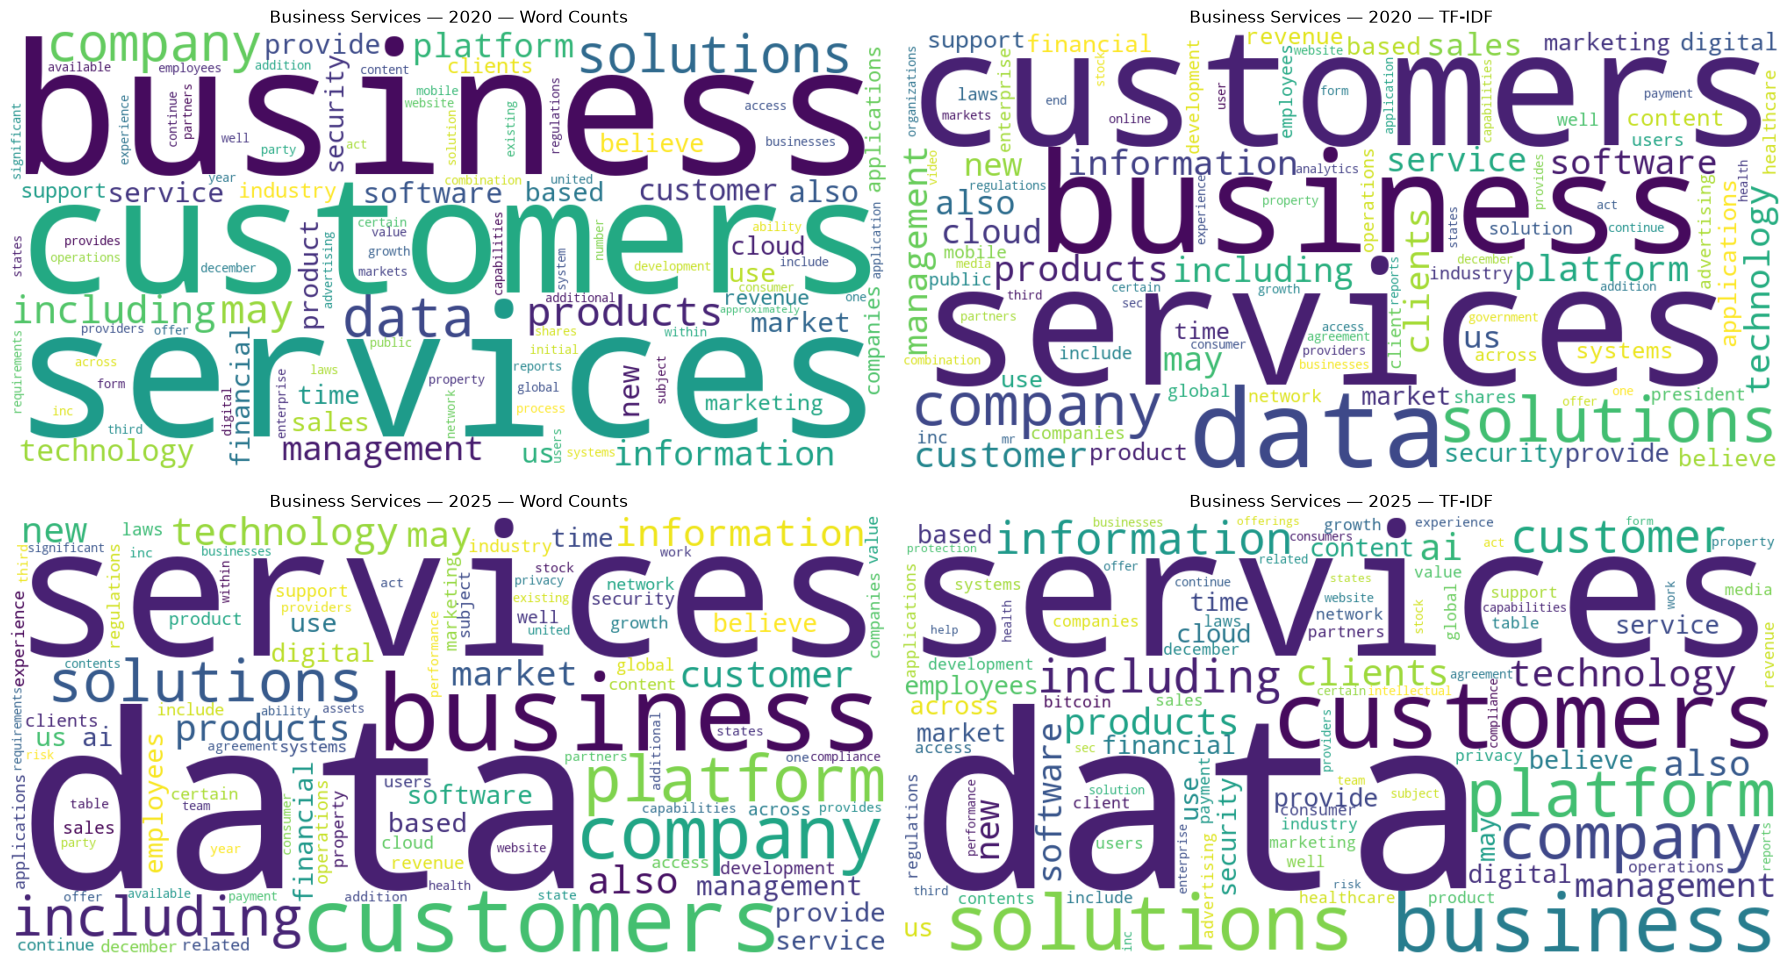

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(18, 10))

for row, year in enumerate([2020, 2025]):
    keywords = results[year]["sector_keywords"]

    print(f"\n{year}: Top 10 sector keywords by word count")
    display(
        keywords.nlargest(10, "word_count")[
            ["keyword", "word_count", "count_share"]
        ].reset_index(drop=True)
    )

    print(f"{year}: Top 10 sector keywords by TF-IDF")
    display(
        keywords.nlargest(10, "tfidf_sum")[
            ["keyword", "tfidf_sum", "tfidf_share"]
        ].reset_index(drop=True)
    )

    for column, (measure, label) in enumerate([
        ("word_count", "Word Counts"),
        ("tfidf_sum", "TF-IDF")
    ]):
        cloud = WordCloud(
            width=1000,
            height=500,
            background_color="white",
            max_words=100,
            collocations=False,
            random_state=42
        ).generate_from_frequencies(
            dict(zip(keywords["keyword"], keywords[measure]))
        )

        axes[row, column].imshow(
            cloud, interpolation="bilinear"
        )
        axes[row, column].set_title(
            f"Business Services — {year} — {label}"
        )
        axes[row, column].axis("off")

plt.tight_layout()
plt.show()

In [16]:
def train_word2vec(
    cleaned_texts,
    vector_size=50,
    window=5,
    min_count=5,
    negative_samples=5,
    epochs=3,
    batch_size=512,
    learning_rate=0.025,
    seed=42
):
    rng = np.random.default_rng(seed)

    frequencies = Counter()
    for text in cleaned_texts:
        frequencies.update(text.split())

    vocabulary = sorted(
        word for word, count in frequencies.items()
        if count >= min_count
    )

    if len(vocabulary) < 2:
        raise ValueError("Too few words to train Word2Vec.")

    word_to_id = {
        word: i for i, word in enumerate(vocabulary)
    }

    counts = np.array(
        [frequencies[word] for word in vocabulary],
        dtype=np.float64
    )

    # Negative-sampling distribution.
    negative_probability = counts ** 0.75
    negative_probability /= negative_probability.sum()

    negative_cdf = np.cumsum(negative_probability)
    negative_cdf[-1] = 1.0

    # Subsample frequent words.
    relative_frequency = counts / sum(frequencies.values())
    threshold = 1e-4

    keep_probability = np.minimum(
        1.0,
        (
            np.sqrt(relative_frequency / threshold) + 1
        ) * threshold / relative_frequency
    )

    # Each report remains a separate training document.
    documents = [
        np.array(
            [
                word_to_id[word]
                for word in text.split()
                if word in word_to_id
            ],
            dtype=np.int32
        )
        for text in cleaned_texts
        if text.strip()
    ]

    input_vectors = rng.uniform(
        -0.5 / vector_size,
        0.5 / vector_size,
        size=(len(vocabulary), vector_size)
    ).astype(np.float32)

    output_vectors = np.zeros_like(input_vectors)

    def update_batch(centers, contexts, rate):
        centers = np.asarray(centers, dtype=np.int32)
        contexts = np.asarray(contexts, dtype=np.int32)

        negatives = np.searchsorted(
            negative_cdf,
            rng.random((len(centers), negative_samples))
        ).astype(np.int32)

        # Exclude the true context from negative samples.
        collision = negatives == contexts[:, None]

        while collision.any():
            negatives[collision] = np.searchsorted(
                negative_cdf,
                rng.random(int(collision.sum()))
            )
            collision = negatives == contexts[:, None]

        targets = np.column_stack([contexts, negatives])

        center_vectors = input_vectors[centers].copy()
        target_vectors = output_vectors[targets].copy()

        scores = np.einsum(
            "bd,bkd->bk",
            center_vectors,
            target_vectors
        )

        probabilities = 1 / (
            1 + np.exp(-np.clip(scores, -15, 15))
        )

        labels = np.zeros_like(probabilities)
        labels[:, 0] = 1

        errors = labels - probabilities

        # Sum the per-pair SGD contributions in this batch.
        input_gradient = rate * np.einsum(
            "bk,bkd->bd",
            errors,
            target_vectors
        )

        output_gradient = (
            rate
            * errors[:, :, None]
            * center_vectors[:, None, :]
        )

        np.add.at(input_vectors, centers, input_gradient)

        np.add.at(
            output_vectors,
            targets.ravel(),
            output_gradient.reshape(-1, vector_size)
        )

        # Negative-sampling logistic loss per observed pair.
        loss = (
            np.logaddexp(0, -scores[:, 0])
            + np.logaddexp(0, scores[:, 1:]).sum(axis=1)
        ).sum()

        return float(loss)

    history = []

    for epoch in range(epochs):
        rate = learning_rate * (1 - 0.8 * epoch / epochs)
        centers, contexts = [], []
        total_loss = 0.0
        pair_count = 0

        for document_index in rng.permutation(len(documents)):
            document = documents[document_index]

            document = document[
                rng.random(len(document))
                < keep_probability[document]
            ]

            for position, center in enumerate(document):
                radius = int(rng.integers(1, window + 1))
                start = max(0, position - radius)
                stop = min(len(document), position + radius + 1)

                for context_position in range(start, stop):
                    if context_position == position:
                        continue

                    centers.append(int(center))
                    contexts.append(int(document[context_position]))
                    pair_count += 1

                    if len(centers) == batch_size:
                        total_loss += update_batch(
                            centers, contexts, rate
                        )
                        centers, contexts = [], []

        if centers:
            total_loss += update_batch(centers, contexts, rate)

        if pair_count == 0:
            raise ValueError("No training pairs were generated.")

        if (
            not np.isfinite(input_vectors).all()
            or not np.isfinite(output_vectors).all()
        ):
            raise ValueError(
                "Training became unstable. Reduce learning_rate."
            )

        mean_loss = total_loss / pair_count
        history.append(mean_loss)

        print(
            f"Epoch {epoch + 1}/{epochs}: "
            f"{pair_count:,} pairs, "
            f"mean loss = {mean_loss:.4f}",
            flush=True
        )

    norms = np.linalg.norm(
        input_vectors, axis=1, keepdims=True
    )

    normalized_vectors = input_vectors / np.maximum(norms, 1e-12)

    return {
        "vocabulary": vocabulary,
        "word_to_id": word_to_id,
        "vectors": normalized_vectors,
        "loss_history": history
    }

def most_similar(model, keyword, topn=5):
    keyword = keyword.lower()

    if keyword not in model["word_to_id"]:
        return []

    index = model["word_to_id"][keyword]
    scores = model["vectors"] @ model["vectors"][index]

    # Exclude the query word itself.
    scores[index] = -np.inf
    nearest = np.argsort(-scores)[:topn]

    return [
        (model["vocabulary"][i], float(scores[i]))
        for i in nearest
    ]

In [17]:
models = {}

for year in [2020, 2025]:
    print(f"\nTraining Word2Vec for {year}", flush=True)

    models[year] = train_word2vec(
        cleaned_texts=(
            results[year]["full_sample"]["cleaned_text"].tolist()
        ),
        vector_size=50,
        window=5,
        min_count=5,
        negative_samples=5,
        epochs=3,
        batch_size=512,
        learning_rate=0.025,
        seed=42
    )

    print(
        f"{year} vocabulary: "
        f"{len(models[year]['vocabulary']):,} words"
    )


Training Word2Vec for 2020
Epoch 1/3: 105,553,357 pairs, mean loss = 2.1871
Epoch 2/3: 105,554,584 pairs, mean loss = 2.0907
Epoch 3/3: 105,520,053 pairs, mean loss = 2.0725
2020 vocabulary: 55,630 words

Training Word2Vec for 2025
Epoch 1/3: 108,376,326 pairs, mean loss = 2.1780
Epoch 2/3: 108,345,050 pairs, mean loss = 2.0877
Epoch 3/3: 108,376,896 pairs, mean loss = 2.0712
2025 vocabulary: 54,646 words


In [18]:
selected_keywords = ["software", "services", "customers"]

if len(set(selected_keywords)) != 3:
    raise ValueError("Choose three distinct keywords.")

similarity_rows = []

for year in [2020, 2025]:
    for keyword in selected_keywords:
        neighbors = most_similar(
            models[year], keyword, topn=5
        )

        if not neighbors:
            print(
                f"'{keyword}' is missing from the {year} vocabulary. "
                "Choose a keyword present in both models."
            )
            continue

        for rank, (word, score) in enumerate(neighbors, start=1):
            similarity_rows.append({
                "year": year,
                "keyword": keyword,
                "rank": rank,
                "similar_word": word,
                "cosine_similarity": score
            })

similarity_results = pd.DataFrame(
    similarity_rows,
    columns=[
        "year", "keyword", "rank",
        "similar_word", "cosine_similarity"
    ]
)

for year in [2020, 2025]:
    print(f"\n{year}: Five most similar words per keyword")
    display(
        similarity_results.loc[
            similarity_results["year"] == year
        ].round(4)
    )


2020: Five most similar words per keyword


,year,keyword,rank,similar_word,cosine_similarity
0,2020,software,1,hardware,0.8460
1,2020,software,2,middleware,0.8123
2,2020,software,3,dynatrace,0.8041
3,2020,software,4,storsight,0.7943
4,2020,software,5,certicom,0.7928
5,2020,services,1,rbwm,0.7980
6,2020,services,2,optumhealth,0.7802
7,2020,services,3,qhr,0.7603
8,2020,services,4,iwco,0.7599
9,2020,services,5,presort,0.7574



2025: Five most similar words per keyword


,year,keyword,rank,similar_word,cosine_similarity
15,2025,software,1,hardware,0.8857
16,2025,software,2,spotlightaitm,0.7382
17,2025,software,3,firmware,0.7319
18,2025,software,4,efpga,0.7315
19,2025,software,5,rtls,0.7300
20,2025,services,1,zendit,0.7013
21,2025,services,2,nemt,0.6991
22,2025,services,3,firstech,0.6979
23,2025,services,4,consortiums,0.6923
24,2025,services,5,service,0.6873


In [19]:
keyword_comparison = (
    results[2020]["sector_keywords"]
    .set_index("keyword")[["count_share", "tfidf_share"]]
    .join(
        results[2025]["sector_keywords"]
        .set_index("keyword")[["count_share", "tfidf_share"]],
        how="outer",
        lsuffix="_2020",
        rsuffix="_2025"
    )
    .fillna(0)
)

keyword_comparison["count_change_pp"] = 100 * (
    keyword_comparison["count_share_2025"]
    - keyword_comparison["count_share_2020"]
)

keyword_comparison["tfidf_change_pp"] = 100 * (
    keyword_comparison["tfidf_share_2025"]
    - keyword_comparison["tfidf_share_2020"]
)

for measure, label in [
    ("count_change_pp", "word-count share"),
    ("tfidf_change_pp", "TF-IDF share")
]:
    print(f"\nLargest increases in {label}")
    display(
        keyword_comparison.nlargest(10, measure).round(5)
    )

    print(f"Largest decreases in {label}")
    display(
        keyword_comparison.nsmallest(10, measure).round(5)
    )

# Side-by-side top 10 rankings.
ranking_comparisons = {}

for measure in ["word_count", "tfidf_sum"]:
    tables = []

    for year in [2020, 2025]:
        top = (
            results[year]["sector_keywords"]
            .nlargest(10, measure)[["keyword", measure]]
            .reset_index(drop=True)
        )

        top.columns = [
            f"keyword_{year}", f"{measure}_{year}"
        ]
        tables.append(top)

    comparison_table = pd.concat(tables, axis=1)
    comparison_table.index = range(1, len(comparison_table) + 1)
    comparison_table.index.name = "rank"

    ranking_comparisons[measure] = comparison_table

    print(f"\nTop 10 comparison: {measure}")
    display(comparison_table)


Largest increases in word-count share


,count_share_2020,tfidf_share_2020,count_share_2025,tfidf_share_2025,count_change_pp,tfidf_change_pp
keyword,,,,,,
ai,0.00033,0.00042,0.00282,0.00202,0.24858,0.16054
data,0.00602,0.00319,0.00714,0.00369,0.11134,0.04990
table,0.00032,0.00031,0.00138,0.00101,0.10596,0.07031
contents,0.00027,0.00028,0.00132,0.00103,0.10500,0.07495
platform,0.00395,0.00232,0.00492,0.00267,0.09689,0.03508
employees,0.00206,0.00116,0.00293,0.00169,0.08717,0.05308
bitcoin,0.00015,0.00031,0.00089,0.00117,0.07411,0.08665
employee,0.00046,0.00039,0.00113,0.00076,0.06645,0.03656
digital,0.00206,0.00136,0.00266,0.00155,0.06005,0.01835


Largest decreases in word-count share


,count_share_2020,tfidf_share_2020,count_share_2025,tfidf_share_2025,count_change_pp,tfidf_change_pp
keyword,,,,,,
business,0.00779,0.00372,0.00582,0.00310,-0.19697,-0.06230
services,0.00782,0.00417,0.00639,0.00352,-0.14350,-0.06543
combination,0.00176,0.00081,0.00052,0.00032,-0.12443,-0.04841
initial,0.00144,0.00071,0.00031,0.00022,-0.11349,-0.04944
management,0.00412,0.00215,0.00320,0.00176,-0.09220,-0.03947
public,0.00189,0.00094,0.00106,0.00066,-0.08303,-0.02792
may,0.00423,0.00185,0.00341,0.00166,-0.08165,-0.01873
products,0.00440,0.00237,0.00363,0.00206,-0.07647,-0.03103
sales,0.00302,0.00170,0.00226,0.00136,-0.07587,-0.03355



Largest increases in TF-IDF share


,count_share_2020,tfidf_share_2020,count_share_2025,tfidf_share_2025,count_change_pp,tfidf_change_pp
keyword,,,,,,
ai,0.00033,0.00042,0.00282,0.00202,0.24858,0.16054
bitcoin,0.00015,0.00031,0.00089,0.00117,0.07411,0.08665
contents,0.00027,0.00028,0.00132,0.00103,0.10500,0.07495
table,0.00032,0.00031,0.00138,0.00101,0.10596,0.07031
employees,0.00206,0.00116,0.00293,0.00169,0.08717,0.05308
data,0.00602,0.00319,0.00714,0.00369,0.11134,0.04990
mining,0.00011,0.00024,0.00056,0.00071,0.04543,0.04701
employee,0.00046,0.00039,0.00113,0.00076,0.06645,0.03656
platform,0.00395,0.00232,0.00492,0.00267,0.09689,0.03508


... (2 outputs left out)


Top 10 comparison: word_count


,keyword_2020,word_count_2020,keyword_2025,word_count_2025
rank,,,,
1,services,13564,data,14629
2,business,13504,services,13091
3,customers,11066,business,11924
4,data,10445,customers,11921
5,company,9052,company,10489
6,solutions,9047,platform,10094
7,products,7629,solutions,9353
8,may,7334,including,8784
9,including,7167,technology,7996



Top 10 comparison: tfidf_sum


,keyword_2020,tfidf_sum_2020,keyword_2025,tfidf_sum_2025
rank,,,,
1,services,32.658024,data,31.936881
2,customers,29.426173,services,30.430727
3,business,29.108143,customers,30.193976
4,data,24.992661,business,26.778983
5,solutions,24.247249,solutions,24.304737
6,company,22.511538,platform,23.119870
7,products,18.583720,company,21.664355
8,platform,18.174787,including,19.230646
9,customer,17.910216,customer,18.891522


In [20]:
neighbor_rows = []

for keyword in selected_keywords:
    neighbors_2020 = [
        word for word, score
        in most_similar(models[2020], keyword)
    ]

    neighbors_2025 = [
        word for word, score
        in most_similar(models[2025], keyword)
    ]

    if not neighbors_2020 or not neighbors_2025:
        continue

    shared = set(neighbors_2020) & set(neighbors_2025)

    neighbor_rows.append({
        "keyword": keyword,
        "2020_neighbors": ", ".join(neighbors_2020),
        "2025_neighbors": ", ".join(neighbors_2025),
        "shared_neighbors": ", ".join(sorted(shared)),
        "new_2025_neighbors": ", ".join(
            word for word in neighbors_2025
            if word not in neighbors_2020
        ),
        "top5_overlap": len(shared) / 5
    })

neighbor_comparison = pd.DataFrame(neighbor_rows)
display(neighbor_comparison)

firms_2020 = set(results[2020]["sector"]["gvkey"])
firms_2025 = set(results[2025]["sector"]["gvkey"])

print(
    "\nBusiness Services firms with usable reports in both years:",
    len(firms_2020 & firms_2025)
)

,keyword,2020_neighbors,2025_neighbors,shared_neighbors,new_2025_neighbors,top5_overlap
0,software,"hardware, middleware, dynatrace, storsight, ce...","hardware, spotlightaitm, firmware, efpga, rtls",hardware,"spotlightaitm, firmware, efpga, rtls",0.2
1,services,"rbwm, optumhealth, qhr, iwco, presort","zendit, nemt, firstech, consortiums, service",,"zendit, nemt, firstech, consortiums, service",0.0
2,customers,"ccas, customer, shopfast, finapps, msps","billers, users, businesses, lifecycles, demanded",,"billers, users, businesses, lifecycles, demanded",0.0



Business Services firms with usable reports in both years: 306


## 4. Identify Microsoft's closest text peers

Rank other Business Services firms by cosine similarity to Microsoft's full 2020 TF-IDF representation. Inspect how selected themes differ between Microsoft and the five highest-scoring firms. Filing-text similarity provides an exploratory peer screen.


In [21]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

# Part D constructed tfidf_matrix using this exact DataFrame order.
g_firms = analysis_firms.copy().reset_index(drop=True)

if tfidf_matrix.shape[0] != len(g_firms):
    raise ValueError(
        "Rerun Part D: tfidf_matrix and analysis_firms must "
        "contain the same firms in the same order."
    )

ms_mask = (
    g_firms["conm"]
    .fillna("")
    .str.contains(r"\bmicrosoft\b", case=False, regex=True)
)

if ms_mask.sum() != 1:
    display(g_firms.loc[ms_mask, ["gvkey", "conm"]])
    raise ValueError("Expected exactly one Microsoft record.")

ms_position = np.flatnonzero(ms_mask.to_numpy())[0]
ms_gvkey = g_firms.loc[ms_position, "gvkey"]

# Compare every firm's full TF-IDF representation with Microsoft.
similarities = cosine_similarity(
    tfidf_matrix,
    tfidf_matrix.getrow(ms_position)
).ravel()

g_firms["similarity_to_microsoft"] = similarities

top_peers = (
    g_firms.loc[g_firms["gvkey"] != ms_gvkey]
    .nlargest(5, "similarity_to_microsoft")
    .copy()
)

# Attach your actual D.2 keywords for interpretation.
keyword_lists = (
    top10_tfidf
    .sort_values(["gvkey", "rank"])
    .groupby("gvkey", as_index=False)
    .agg(keywords=("keyword", list))
)

peer_results = top_peers.merge(
    keyword_lists,
    on="gvkey",
    how="left",
    validate="one_to_one"
)

display(
    peer_results[
        ["conm", "gvkey", "similarity_to_microsoft", "keywords"]
    ].style.format({
        "similarity_to_microsoft": "{:.4f}"
    })
)

,conm,gvkey,similarity_to_microsoft,keywords
0,F5 INC,121077,0.4035,"['nginx', 'vice', 'president', 'shape', 'big', 'silverline', 'viprion', 'customers', 'ip', 'application']"
1,SALESFORCE INC,157855,0.3980,"['customers', 'customer', 'salesforce', 'cloud', 'service', 'platform', 'apps', 'companies', 'business', 'offerings']"
2,OPEN TEXT CORP,61870,0.3868,"['opentext', 'cloud', 'information', 'services', 'customer', 'solutions', 'customers', 'business', 'management', 'carbonite']"
3,VMWARE INC -CL A,178083,0.3493,"['vmware', 'cloud', 'vsphere', 'virtualization', 'dell', 'aws', 'clouds', 'vice', 'vcpp', 'president']"
4,PROGRESS SOFTWARE CORP,24352,0.3476,"['openedge', 'products', 'progress', 'application', 'business', 'applications', 'datadirect', 'oems', 'data', 'partners']"


In [22]:
focus_keywords = [
    "software", "cloud", "enterprise", "platform", "customer"
]

term_to_column = {
    term: position for position, term in enumerate(terms)
}

available = [
    word for word in focus_keywords if word in term_to_column
]

print(
    "Keywords absent from the Part D vocabulary:",
    [word for word in focus_keywords if word not in term_to_column]
)

if not available:
    raise ValueError("None of the selected themes is in the vocabulary.")

peer_positions = top_peers.index.to_numpy()
selected_positions = [ms_position] + peer_positions.tolist()

columns = [term_to_column[word] for word in available]

theme_values = (
    tfidf_matrix[selected_positions][:, columns].toarray()
)

theme_table = pd.DataFrame(
    theme_values,
    columns=available
)

theme_table.insert(
    0,
    "Firm",
    g_firms.loc[selected_positions, "conm"].to_numpy()
)

display(
    theme_table.style.format({
        word: "{:.4f}" for word in available
    })
)

theme_summary = pd.DataFrame({
    "Theme": available,
    "Microsoft TF-IDF": theme_values[0],
    "Peer mean TF-IDF": theme_values[1:].mean(axis=0)
})

theme_summary["Microsoft minus peer mean"] = (
    theme_summary["Microsoft TF-IDF"]
    - theme_summary["Peer mean TF-IDF"]
)

display(
    theme_summary.style.format({
        "Microsoft TF-IDF": "{:.4f}",
        "Peer mean TF-IDF": "{:.4f}",
        "Microsoft minus peer mean": "{:.4f}"
    })
)

Keywords absent from the Part D vocabulary: []


,Firm,software,cloud,enterprise,platform,customer
0,MICROSOFT CORP,0.1095,0.1740,0.0650,0.0384,0.0304
1,F5 INC,0.0721,0.1214,0.0430,0.0262,0.0481
2,SALESFORCE INC,0.0885,0.2426,0.0784,0.1784,0.2604
3,OPEN TEXT CORP,0.0914,0.2063,0.0527,0.0659,0.1730
4,VMWARE INC -CL A,0.0917,0.3214,0.0408,0.0663,0.0170
5,PROGRESS SOFTWARE CORP,0.0980,0.0607,0.0135,0.0384,0.0534


,Theme,Microsoft TF-IDF,Peer mean TF-IDF,Microsoft minus peer mean
0,software,0.1095,0.0883,0.0212
1,cloud,0.1740,0.1905,-0.0164
2,enterprise,0.0650,0.0457,0.0194
3,platform,0.0384,0.0750,-0.0366
4,customer,0.0304,0.1104,-0.0800


## 5. Benchmark financials and examine historical trends

Compare Microsoft and its five selected peers using fiscal 2020 results. This benchmark defines return on assets as net income divided by ending assets. Sector sample share uses each firm's sales divided by reported nonnegative 2020 sales in the supplied SIC 73 sample. The final cells examine Microsoft's historical levels and year-over-year changes.


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

data = firms.copy()
data.columns = data.columns.str.strip().str.lower()

for column in [
    "gvkey", "fyear", "sic", "sale",
    "asset", "net_income", "prcc_c"
]:
    data[column] = pd.to_numeric(data[column], errors="coerce")

ms_id = int(ms_gvkey)
peer_ids = pd.to_numeric(
    top_peers["gvkey"], errors="coerce"
).dropna().astype(int).tolist()

selected_ids = list(dict.fromkeys([ms_id] + peer_ids))

# Calculate ROA consistently for every firm-year.
data["ROA_pct"] = (
    data["net_income"]
    / data["asset"].where(data["asset"] > 0)
    * 100
)

# Compare financial results in the same year as the 2020 reports.
comparison_2020 = data.loc[
    data["fyear"].eq(2020)
    & data["gvkey"].isin(selected_ids)
].copy()

if comparison_2020["gvkey"].duplicated().any():
    raise ValueError("Duplicate firm-year records found.")

if ms_id not in comparison_2020["gvkey"].values:
    raise ValueError("Microsoft's 2020 financial record is missing.")

# Market-share proxy: share of all available Business Services sales.
sector_2020 = data.loc[
    data["fyear"].eq(2020)
    & data["sic"].floordiv(100).eq(73)
].copy()

sector_sales = sector_2020.loc[
    sector_2020["sale"].ge(0), "sale"
].sum(min_count=1)

if pd.isna(sector_sales) or sector_sales <= 0:
    raise ValueError("Sector sales denominator is unavailable.")

comparison_2020["sector_sample_share_pct"] = (
    comparison_2020["sale"].where(comparison_2020["sale"] >= 0)
    / sector_sales * 100
)

comparison_2020["is_microsoft"] = (
    comparison_2020["gvkey"] == ms_id
)

comparison_2020 = comparison_2020.sort_values(
    ["is_microsoft", "sale"],
    ascending=[False, False]
)

display(
    comparison_2020[
        [
            "conm", "sale", "asset", "net_income",
            "ROA_pct", "sector_sample_share_pct"
        ]
    ].round(3)
)

print(
    "Revenue and assets retain the CSV's units. "
    "Sector sample share is a dataset-based market-share proxy, "
    "not Microsoft's global software or cloud market share."
)

,conm,sale,asset,net_income,ROA_pct,sector_sample_share_pct
48611,MICROSOFT CORP,143015.000,301311.000,44281.000,14.696,9.504
212169,SALESFORCE INC,21252.000,66301.000,4072.000,6.142,1.412
228667,VMWARE INC -CL A,11767.000,29016.000,2058.000,7.093,0.782
150137,OPEN TEXT CORP,3109.736,10234.822,234.225,2.289,0.207
188834,F5 INC,2350.822,4677.920,307.441,6.572,0.156
91702,PROGRESS SOFTWARE CORP,442.150,1041.782,79.722,7.652,0.029


Revenue and assets retain the CSV's units. Sector sample share is a dataset-based market-share proxy, not Microsoft's global software or cloud market share.


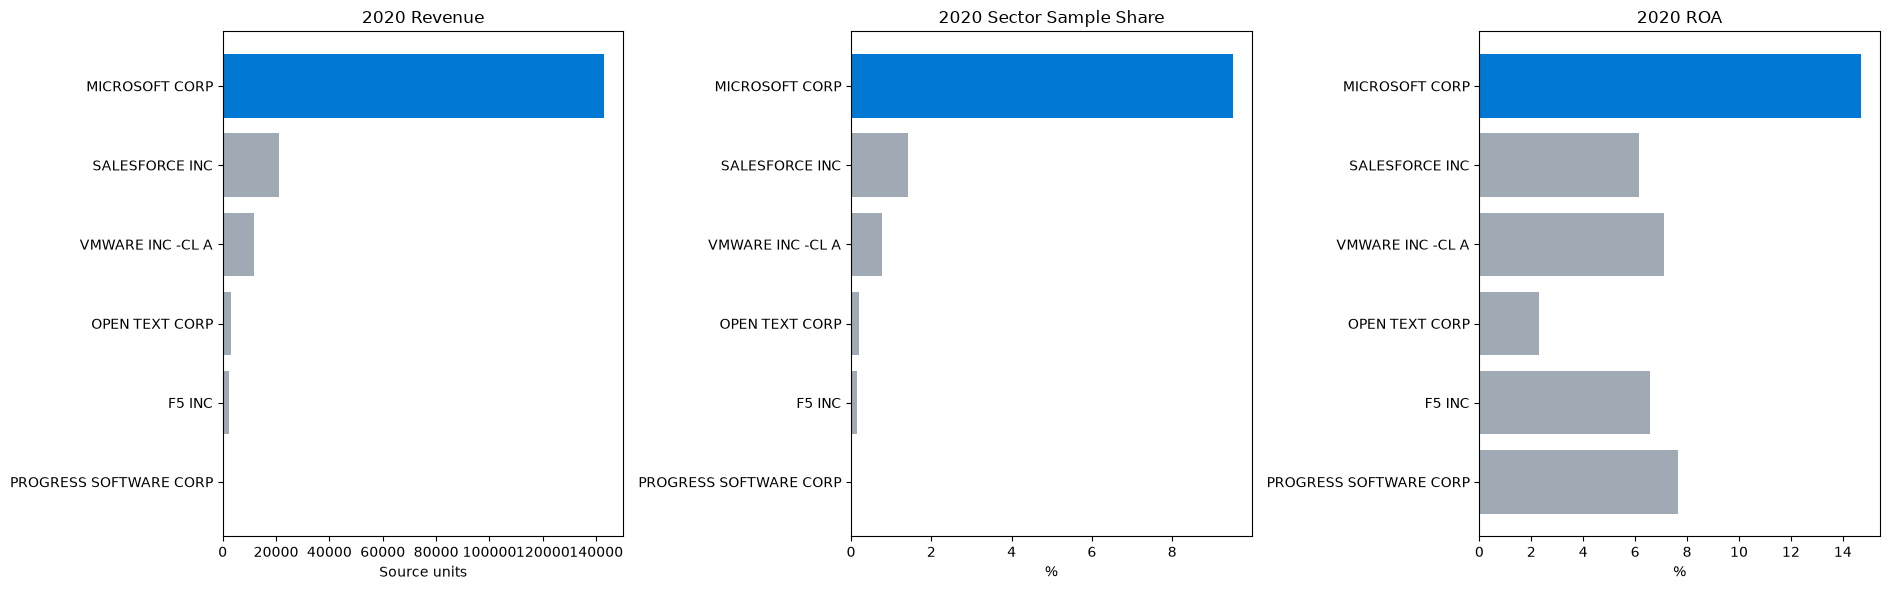

,Microsoft,Competitor median
sale,143015.000,3109.736
sector_sample_share_pct,9.504,0.207
ROA_pct,14.696,6.572


Microsoft's revenue (143,015.00) is above the competitor median (3,109.74).
Microsoft's sector sample share (9.50) is above the competitor median (0.21).
Microsoft's ROA (14.70) is above the competitor median (6.57).


In [24]:
plot_data = comparison_2020.copy()

colors = [
    "#0078D4" if firm_id == ms_id else "#A0AAB4"
    for firm_id in plot_data["gvkey"]
]

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

measures = [
    ("sale", "2020 Revenue", "Source units"),
    ("sector_sample_share_pct", "2020 Sector Sample Share", "%"),
    ("ROA_pct", "2020 ROA", "%")
]

for ax, (column, title, xlabel) in zip(axes, measures):
    ax.barh(plot_data["conm"], plot_data[column], color=colors)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.invert_yaxis()
    ax.axvline(0, color="black", linewidth=0.7)

plt.tight_layout()
plt.show()

# Compare Microsoft with the median selected competitor.
metrics = ["sale", "sector_sample_share_pct", "ROA_pct"]

ms_values = comparison_2020.loc[
    comparison_2020["gvkey"].eq(ms_id)
].iloc[0]

peers = comparison_2020.loc[
    comparison_2020["gvkey"].ne(ms_id)
]

benchmark = pd.DataFrame({
    "Microsoft": ms_values[metrics].astype(float),
    "Competitor median": peers[metrics].median()
})

display(benchmark.round(3))

for metric, label in [
    ("sale", "revenue"),
    ("sector_sample_share_pct", "sector sample share"),
    ("ROA_pct", "ROA")
]:
    ms_value = benchmark.loc[metric, "Microsoft"]
    peer_value = benchmark.loc[metric, "Competitor median"]

    if pd.notna(ms_value) and pd.notna(peer_value):
        position = (
            "above" if ms_value > peer_value
            else "below" if ms_value < peer_value
            else "equal to"
        )
        print(
            f"Microsoft's {label} ({ms_value:,.2f}) is "
            f"{position} the competitor median ({peer_value:,.2f})."
        )

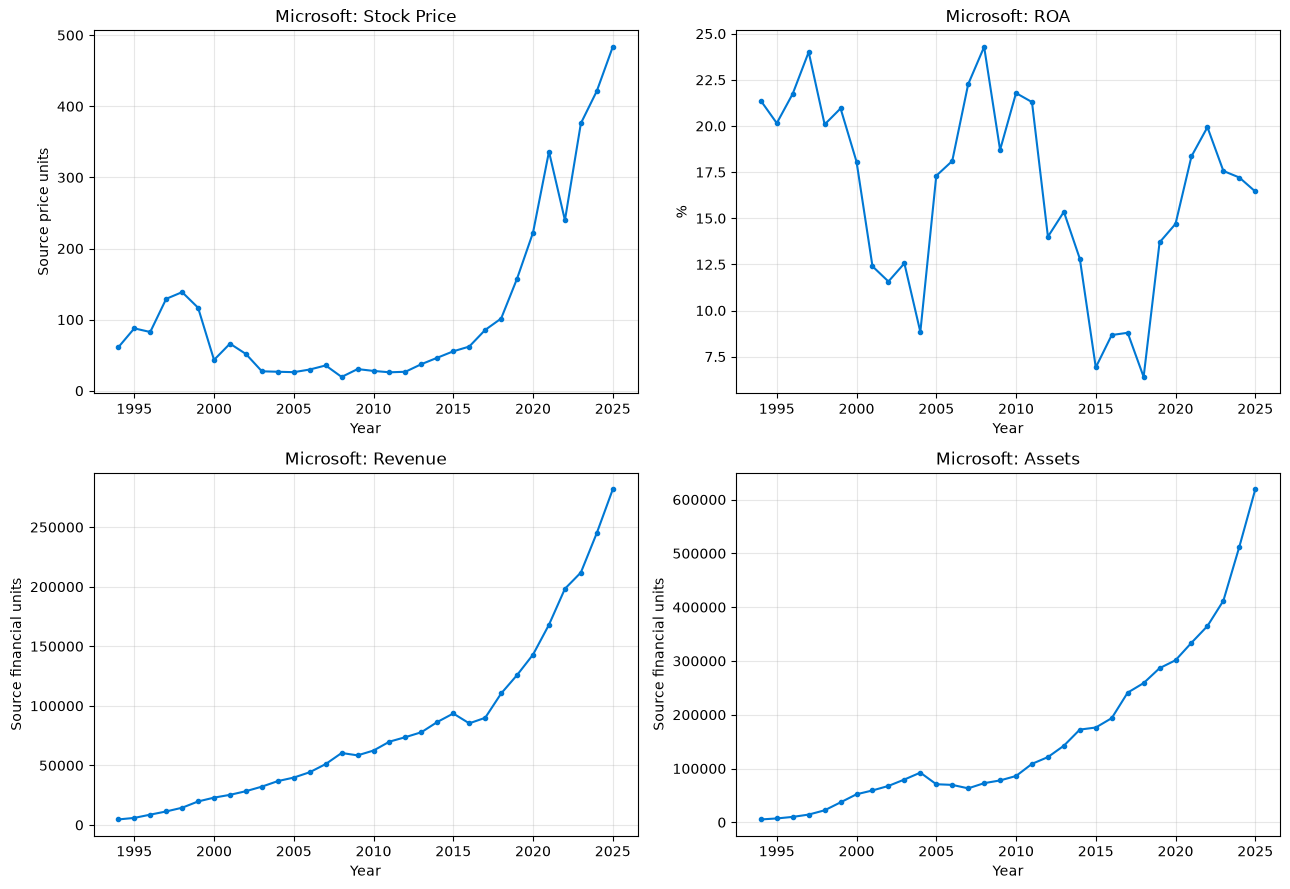

In [25]:
history = (
    data.loc[
        data["gvkey"].eq(ms_id),
        ["fyear", "prcc_c", "sale", "asset", "net_income", "ROA_pct"]
    ]
    .dropna(subset=["fyear"])
    .sort_values("fyear")
    .copy()
)

if history["fyear"].duplicated().any():
    raise ValueError("Duplicate Microsoft firm-year records found.")

history["fyear"] = history["fyear"].astype(int)
history = history.set_index("fyear")

# Preserve missing years rather than calculating changes across gaps.
history = history.reindex(
    range(history.index.min(), history.index.max() + 1)
)
history.index.name = "fyear"

for column in ["prcc_c", "sale", "asset"]:
    previous = history[column].shift(1)
    history[f"{column}_growth_pct"] = (
        (history[column] / previous.where(previous > 0) - 1)
        * 100
    )

# ROA changes are expressed in percentage points.
history["ROA_change_pp"] = history["ROA_pct"].diff()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

plots = [
    ("prcc_c", "Stock Price", "Source price units"),
    ("ROA_pct", "ROA", "%"),
    ("sale", "Revenue", "Source financial units"),
    ("asset", "Assets", "Source financial units")
]

for ax, (column, title, ylabel) in zip(axes.flat, plots):
    ax.plot(
        history.index,
        history[column],
        marker="o",
        markersize=3,
        color="#0078D4"
    )
    ax.set_title(f"Microsoft: {title}")
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
change_measures = {
    "prcc_c_growth_pct": "Stock price change (%)",
    "sale_growth_pct": "Revenue change (%)",
    "asset_growth_pct": "Asset change (%)",
    "ROA_change_pp": "ROA change (percentage points)"
}

events = []

for column, label in change_measures.items():
    values = history[column].dropna()

    if values.empty:
        continue

    for movement, year in [
        ("Largest increase", values.idxmax()),
        ("Largest decrease", values.idxmin())
    ]:
        events.append({
            "Measure": label,
            "Movement": movement,
            "Year": year,
            "Change": values.loc[year],
            "Revenue": history.loc[year, "sale"],
            "Net income": history.loc[year, "net_income"],
            "Assets": history.loc[year, "asset"],
            "ROA (%)": history.loc[year, "ROA_pct"]
        })

display(pd.DataFrame(events).round(3))

,Measure,Movement,Year,Change,Revenue,Net income,Assets,ROA (%)
0,Stock price change (%),Largest increase,2023,56.801,211915.0,72361.0,411976.0,17.564
1,Stock price change (%),Largest decrease,2000,-62.848,22956.0,9421.0,52150.0,18.065
2,Revenue change (%),Largest increase,1996,46.050,8671.0,2195.0,10093.0,21.748
3,Revenue change (%),Largest decrease,2016,-8.827,85320.0,16798.0,193694.0,8.672
4,Asset change (%),Largest increase,1999,66.194,19747.0,7785.0,37156.0,20.952
5,Asset change (%),Largest decrease,2005,-23.351,39788.0,12254.0,70815.0,17.304
6,ROA change (percentage points),Largest increase,2005,8.463,39788.0,12254.0,70815.0,17.304
7,ROA change (percentage points),Largest decrease,2012,-7.296,73723.0,16978.0,121271.0,14.000


In [27]:
levels = history[
    ["prcc_c", "ROA_pct", "sale", "asset"]
].rename(columns={
    "prcc_c": "Stock price",
    "ROA_pct": "ROA",
    "sale": "Revenue",
    "asset": "Assets"
})

changes = history[
    [
        "prcc_c_growth_pct",
        "ROA_change_pp",
        "sale_growth_pct",
        "asset_growth_pct"
    ]
].rename(columns=change_measures)

print("Correlation between levels:")
display(levels.corr(min_periods=3).round(3))

print("Correlation between annual changes:")
display(changes.corr(min_periods=3).round(3))

Correlation between levels:


,Stock price,ROA,Revenue,Assets
Stock price,1.000,0.077,0.854,0.862
ROA,0.077,1.000,-0.151,-0.250
Revenue,0.854,-0.151,1.000,0.986
Assets,0.862,-0.250,0.986,1.000


Correlation between annual changes:


,Stock price change (%),ROA change (percentage points),Revenue change (%),Asset change (%)
Stock price change (%),1.000,-0.038,-0.169,-0.156
ROA change (percentage points),-0.038,1.000,0.135,-0.241
Revenue change (%),-0.169,0.135,1.000,0.624
Asset change (%),-0.156,-0.241,0.624,1.000


,sale,asset,net_income,net_profit_margin_pct,asset_turnover,ROA_pct
fyear,,,,,,
2020,143015.0,301311.0,44281.0,30.962,0.475,14.696
2021,168088.0,333779.0,61271.0,36.452,0.504,18.357
2022,198270.0,364840.0,72738.0,36.686,0.543,19.937
2023,211915.0,411976.0,72361.0,34.146,0.514,17.564
2024,245122.0,512163.0,88136.0,35.956,0.479,17.209
2025,281724.0,619003.0,101832.0,36.146,0.455,16.451


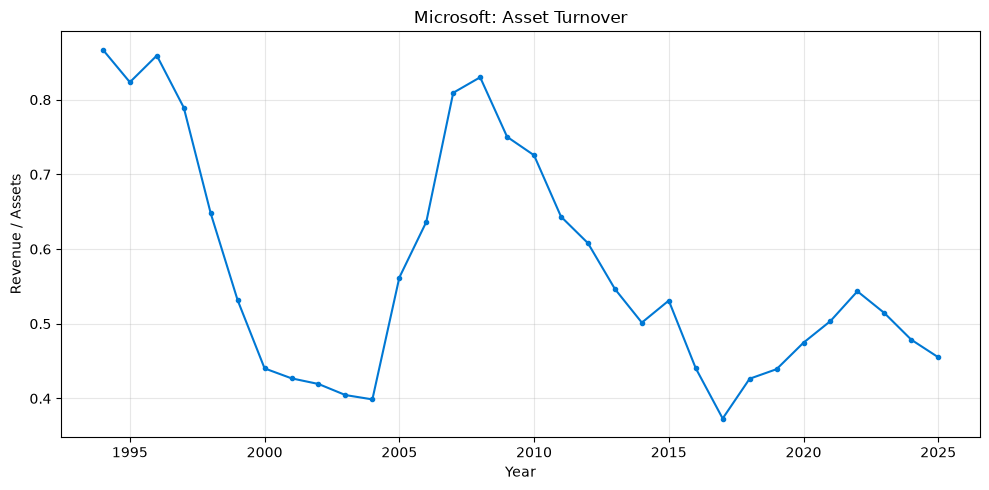

In [28]:
history["asset_turnover"] = (
    history["sale"]
    / history["asset"].where(history["asset"] > 0)
)

history["net_profit_margin_pct"] = (
    history["net_income"]
    / history["sale"].where(history["sale"] > 0)
    * 100
)

# ROA (%) = net profit margin (%) × asset turnover.
display(
    history.loc[
        2020:2025,
        [
            "sale", "asset", "net_income",
            "net_profit_margin_pct", "asset_turnover", "ROA_pct"
        ]
    ].round(3)
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    history.index,
    history["asset_turnover"],
    marker="o",
    markersize=3,
    color="#0078D4"
)
ax.set_title("Microsoft: Asset Turnover")
ax.set_xlabel("Year")
ax.set_ylabel("Revenue / Assets")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()